In [1]:
!pip install -q mediapipe==0.10.14 deepface kagglehub

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 35.7/35.7 MB 36.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 170.7/170.7 kB 9.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 115.9/115.9 kB 6.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 212.0/212.0 kB 14.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 70.4/70.4 kB 4.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.9/1.9 MB 59.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 295.2/295.2 kB 16.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 645.0/645.0 MB 1.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 51.3/51.3 kB 2.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 16.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.5/5.5 MB 15.2 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the sou

In [2]:
import os
import csv
import cv2
import torch
import numpy as np
import kagglehub
import mediapipe as mp
import shutil
from pathlib import Path
from tqdm import tqdm
from google.colab import drive
import gc

# =============================================================================
# إعدادات لسرعة جنونية (خفض الإطارات)
# =============================================================================
drive.mount('/content/drive')
cv2.setNumThreads(os.cpu_count())

TARGET_FPS = 10.0
WINDOW_SEC = 5.0
STRIDE_SEC = 3.0

WINDOW_FRAMES = int(WINDOW_SEC * TARGET_FPS)
STRIDE_FRAMES = int(STRIDE_SEC * TARGET_FPS)
EXPECTED_DIM = 132
ENGAGEMENT_COL = "Engagement"

BATCH_SIZE_VIDEOS = 100

LOCAL_CACHE_DIR = Path("/content/local_cache/body_features")
DRIVE_OUTPUT_DIR = Path("/content/drive/MyDrive/TriVex/heads/engagementHead/data/cache/daisee_body_batches")
DRIVE_OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
LOG_FILE = DRIVE_OUTPUT_DIR / "processed_videos_log.txt"

# =============================================================================
# التحميل والتجهيز
# =============================================================================
_dl_path = kagglehub.dataset_download("olgaparfenova/daisee")
DAISEE_ROOT = Path(_dl_path)

def _get_labels_path(split: str) -> Path:
    return DAISEE_ROOT / "DAiSEE" / "Labels" / {
        "train": "TrainLabels.csv", "val": "ValidationLabels.csv", "test": "TestLabels.csv"
    }[split]

def _get_data_path(split: str) -> Path:
    return DAISEE_ROOT / "DAiSEE" / "DataSet" / {
        "train": "Train", "val": "Validation", "test": "Test"
    }[split]

def _load_labels(labels_csv: Path):
    labels = {}
    with open(labels_csv, newline="", encoding="utf-8-sig") as f:
        for row in csv.DictReader(f):
            labels[Path(row["ClipID"].strip()).stem] = int(row[ENGAGEMENT_COL])
    return labels

def load_processed_log():
    if not LOG_FILE.exists(): return set()
    with open(LOG_FILE, "r") as f: return set(line.strip() for line in f.readlines())

def append_to_log(clip_stems):
    with open(LOG_FILE, "a") as f:
        for stem in clip_stems: f.write(f"{stem}\n")

# =============================================================================
# المستخرج
# =============================================================================
class BodyFeatureExtractor:
    def __init__(self):
        self.pose = mp.solutions.pose.Pose(
            static_image_mode=False,
            model_complexity=0,
            smooth_landmarks=False,
            min_detection_confidence=0.5,
            min_tracking_confidence=0.5
        )

    def extract(self, frame):
        rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
        res = self.pose.process(rgb)
        if not res.pose_landmarks: return np.zeros(EXPECTED_DIM, dtype=np.float32)
        arr = []
        for lm in res.pose_landmarks.landmark:
            arr.extend([lm.x, lm.y, lm.z, lm.visibility])
        return np.array(arr, dtype=np.float32)

def extract_windows_from_video(video_path: str):
    cap = cv2.VideoCapture(video_path)
    if not cap.isOpened(): return None

    fps = cap.get(cv2.CAP_PROP_FPS)
    if fps <= 0: fps = 30.0

    interval = max(1, int(round(fps / TARGET_FPS)))
    frames = []
    count = 0
    while True:
        ret, frame = cap.read()
        if not ret: break
        if count % interval == 0:
            frames.append(frame)
        count += 1
    cap.release()

    if not frames: return None
    windows = []
    start = 0
    max_start = len(frames) - WINDOW_FRAMES

    if len(frames) < WINDOW_FRAMES:
        windows.append(frames + [frames[-1]] * (WINDOW_FRAMES - len(frames)))
        return windows

    while start <= max_start:
        windows.append(frames[start:start + WINDOW_FRAMES])
        start += STRIDE_FRAMES

    return windows

# =============================================================================
# التنفيذ (محدث لدعم الاستكمال التلقائي)
# =============================================================================
def precompute_daisee_body_fastest(splits=("train", "val", "test")):
    processed_clips = load_processed_log()
    print(f"🔄 تم العثور على {len(processed_clips)} فيديو معالج مسبقاً في السجل.")

    tasks = []

    for split in splits:
        labels_csv = _get_labels_path(split)
        split_dir = _get_data_path(split)
        if not labels_csv.exists() or not split_dir.exists(): continue

        labels = _load_labels(labels_csv)
        video_files = sorted(list(split_dir.rglob("*.avi")) + list(split_dir.rglob("*.mp4")))

        for video_path in video_files:
            clip_stem = video_path.stem
            # لو الفيديو اتعمل قبل كده، هيتجاهله تماماً
            if clip_stem in processed_clips: continue

            label = labels.get(clip_stem)
            if label is not None:
                tasks.append((str(video_path), label, split, video_path.parents[1].name, clip_stem))

    if not tasks:
        print("🎉 مفيش فيديوهات ناقصة، الداتا كلها خلصت!")
        return

    # >>> التعديل هنا: تحديد رقم الباتش اللي عليه الدور بناءً على الملفات اللي ع الدرايف <<<
    existing_zips = len(list(DRIVE_OUTPUT_DIR.glob("batch_*.zip")))
    next_batch_num = existing_zips + 1
    print(f"📦 تم العثور على {existing_zips} باتش جاهزين ع الدرايف. هنكمل شغل بداية من batch_{next_batch_num:04d}.zip")

    extractor = BodyFeatureExtractor()
    total_batches = (len(tasks) + BATCH_SIZE_VIDEOS - 1) // BATCH_SIZE_VIDEOS

    for batch_idx in range(total_batches):
        batch_tasks = tasks[batch_idx * BATCH_SIZE_VIDEOS : (batch_idx + 1) * BATCH_SIZE_VIDEOS]

        if LOCAL_CACHE_DIR.exists(): shutil.rmtree(LOCAL_CACHE_DIR)
        LOCAL_CACHE_DIR.mkdir(parents=True, exist_ok=True)

        completed_stems = []
        # تحديد اسم الباتش الحالي بشكل صحيح
        current_batch_name = f"batch_{next_batch_num + batch_idx:04d}"

        for task in tqdm(batch_tasks, desc=f"معالجة {current_batch_name}"):
            video_path, label, split, subject, clip_stem = task
            out_dir = LOCAL_CACHE_DIR / split / subject
            out_dir.mkdir(parents=True, exist_ok=True)

            windows = extract_windows_from_video(video_path)
            if not windows: continue

            for i, w_frames in enumerate(windows):
                try:
                    features = np.array([extractor.extract(f) for f in w_frames], dtype=np.float32)
                    torch.save({
                        "body_feature": torch.tensor(features),
                        "label": np.int64(label),
                        "meta": {"split": split, "subject": subject, "clip": clip_stem, "window_idx": i}
                    }, out_dir / f"{clip_stem}_w{i:03d}.pt")
                except Exception: pass

            completed_stems.append(clip_stem)
            del windows
            gc.collect()

        # ضغط ورفع الباتش الحالي بالاسم الصحيح
        shutil.make_archive(f"/content/{current_batch_name}", 'zip', LOCAL_CACHE_DIR)
        shutil.move(f"/content/{current_batch_name}.zip", str(DRIVE_OUTPUT_DIR / f"{current_batch_name}.zip"))
        append_to_log(completed_stems)

if __name__ == "__main__":
    precompute_daisee_body_fastest()

Mounted at /content/drive


100%|██████████| 14.3G/14.3G [02:41<00:00, 94.8MB/s]

Extracting files...


🔄 تم العثور على 6457 فيديو معالج مسبقاً في السجل.
📦 تم العثور على 65 باتش جاهزين ع الدرايف. هنكمل شغل بداية من batch_0066.zip


معالجة batch_0066:   0%|          | 0/100 [00:00<?, ?it/s]/usr/local/lib/python3.12/dist-packages/google/protobuf/symbol_database.py:55: UserWarning: SymbolDatabase.GetPrototype() is deprecated. Please use message_factory.GetMessageClass() instead. SymbolDatabase.GetPrototype() will be removed soon.
  warnings.warn('SymbolDatabase.GetPrototype() is deprecated. Please '
معالجة batch_0087: 100%|██████████| 14/14 [01:03<00:00,  4.53s/it]


📦 جاري فك ضغط الباتش الأول...

📄 بنعمل Test على الملف: 2100571007_w000.pt
--------------------------------------------------
📏 شكل مصفوفة الجسم: torch.Size([50, 132])
✅ الأبعاد صحيحة 100% (50 إطار، 132 ميزة)
🏷️ الـ Label (التفاعل): 1
ℹ️ معلومات الـ Meta: {'split': 'train', 'subject': '210057', 'clip': '2100571007', 'window_idx': 0}

⚠️ نسبة الأصفار في الـ Tensor: 0.00%
✅ الداتا سليمة وفيها حركة فعلية.



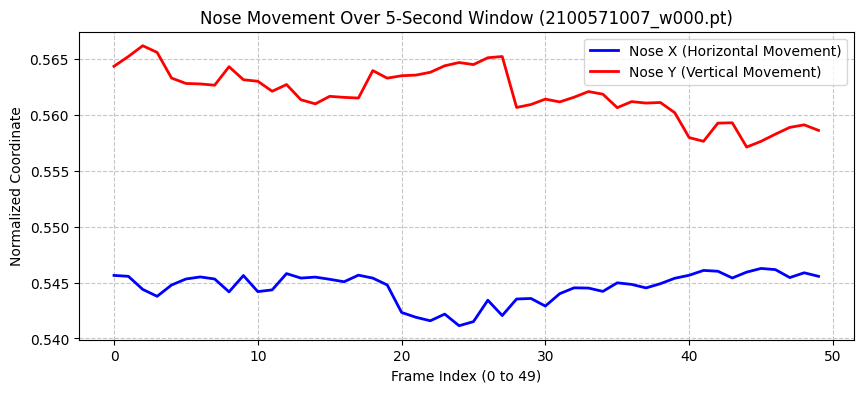

In [3]:
import zipfile
import torch
import matplotlib.pyplot as plt
from pathlib import Path
import random
import shutil

# مسار ملف الـ zip بتاع أول باتش
ZIP_PATH = "/content/drive/MyDrive/TriVex/heads/engagementHead/data/cache/daisee_body_batches/batch_0001.zip"
EXTRACT_DIR = Path("/content/test_batch_extracted")

print("📦 جاري فك ضغط الباتش الأول...")
if EXTRACT_DIR.exists():
    shutil.rmtree(EXTRACT_DIR)
EXTRACT_DIR.mkdir(parents=True)

with zipfile.ZipFile(ZIP_PATH, 'r') as zip_ref:
    zip_ref.extractall(EXTRACT_DIR)

# تجميع كل ملفات الـ .pt واختيار واحد عشوائي
pt_files = list(EXTRACT_DIR.rglob("*.pt"))

if not pt_files:
    print("❌ مفيش ملفات .pt طلعت! راجع كود الاستخراج.")
else:
    sample_file = random.choice(pt_files)
    print(f"\n📄 بنعمل Test على الملف: {sample_file.name}")
    print("-" * 50)

    # 1. تحميل الداتا
    data = torch.load(sample_file, weights_only=False)
    body_feat = data["body_feature"]

    # 2. فحص الأبعاد
    print(f"📏 شكل مصفوفة الجسم: {body_feat.shape}")
    if body_feat.shape == (50, 132):
        print("✅ الأبعاد صحيحة 100% (50 إطار، 132 ميزة)")
    else:
        print("❌ في مشكلة في الأبعاد!")

    print(f"🏷️ الـ Label (التفاعل): {data['label']}")
    print(f"ℹ️ معلومات الـ Meta: {data['meta']}\n")

    # 3. اختبار الأصفار (لو MediaPipe ملقطش الشخص)
    zero_ratio = (body_feat == 0).float().mean().item()
    print(f"⚠️ نسبة الأصفار في الـ Tensor: {zero_ratio * 100:.2f}%")
    if zero_ratio > 0.9:
        print("❌ الـ Tensor أغلبه أصفار! (احتمال الشخص مش ظاهر أو الإضاءة سيئة)")
    else:
        print("✅ الداتا سليمة وفيها حركة فعلية.\n")

    # 4. رسم بياني لحركة الأنف (Nose) على مدار 50 إطار
    # النقطة رقم 0 هي الأنف (x, y)
    nose_x = body_feat[:, 0].numpy()
    nose_y = body_feat[:, 1].numpy()

    plt.figure(figsize=(10, 4))
    plt.plot(nose_x, label="Nose X (Horizontal Movement)", color='blue', linewidth=2)
    plt.plot(nose_y, label="Nose Y (Vertical Movement)", color='red', linewidth=2)
    plt.title(f"Nose Movement Over 5-Second Window ({sample_file.name})")
    plt.xlabel("Frame Index (0 to 49)")
    plt.ylabel("Normalized Coordinate")
    plt.legend()
    plt.grid(True, linestyle='--', alpha=0.7)
    plt.show()